# Comparación con NLP: spaCy y Transformers

**Responsable:** Persona 1

Se procesa el conjunto de prueba (`data/test_set.csv`) con dos herramientas de NLP para español y se
guardan las salidas en el formato acordado (`docs/gramatica_es.md`, sección 2.4):

| Herramienta | Salida |
| --- | --- |
| spaCy `es_core_news_sm` | `results/spacy.jsonl` |
| Modelo de HuggingFace Transformers para español | `results/transformers.jsonl` |

Ninguna de las dos decide si la oración es válida (`acepta` = `null`): se comparan por **etiquetado** y,
spaCy, por **funciones sintácticas** (sujeto, verbo y objeto). La conversión a nuestras categorías es la de
la sección 2.5, implementada en `experiments/tagsets.py`.

**Antes de correrlo** (una sola vez, con el `.venv` del proyecto activado):

```bash
pip install -r requirements.txt -r requirements-experiments.txt
python -m spacy download es_core_news_sm
```

Preguntas que este notebook debe responder (van al informe):

1. ¿En qué oraciones spaCy y Transformers analizan bien lo que la CFG **no puede**? Pista: `en_gramatica = no` y `espanol_valido = si`.
2. ¿En qué oraciones la CFG acierta y ellos **no**?

In [7]:
# Configuración: el notebook vive en notebooks/, el código del proyecto en la raíz.
import sys
import time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd

from evaluation.formats import Prediction, load_predictions, load_test_set, results_path, save_predictions

pd.set_option("display.max_colwidth", 80)
items = load_test_set()
by_id = {item.id: item for item in items}
print(f"{len(items)} oraciones en el conjunto de prueba")

8 oraciones en el conjunto de prueba


In [8]:
pd.DataFrame([{
    "id": i.id, "nivel": i.level, "oracion": i.sentence,
    "en_gramatica": i.in_grammar, "espanol_valido": i.valid_spanish,
    "tipo_error": i.error_type, "fenomeno": ";".join(i.phenomena),
} for i in items])

,id,nivel,oracion,en_gramatica,espanol_valido,tipo_error,fenomeno
0,1,1,Ella come una manzana.,True,True,NaN,svo
1,2,2,Los perros grandes durmieron.,True,True,NaN,adjetivo;intransitivo;preterito
2,3,2,Él mató un elefante muy gris ayer.,True,True,NaN,intensificador;adverbio;preterito
3,4,3,Él mató un elefante en sus pijamas.,True,True,NaN,ambiguedad;pp
4,5,2,La elefante grises duerme.,False,False,concordancia,concordancia_np
5,6,2,Los perros come.,False,False,concordancia,concordancia_sv
6,7,3,Come la manzana.,False,True,sintactico,sujeto_omitido
7,8,2,Mi niña comió la manzana con su perro.,True,True,NaN,posesivo;pp;preterito


## 1. spaCy

### 1.1 Correr spaCy y guardar `results/spacy.jsonl`

In [9]:
import spacy

try:
    nlp = spacy.load("es_core_news_sm")
except OSError:
    raise SystemExit("Falta el modelo: python -m spacy download es_core_news_sm")

# Anotar en el informe: versión de spaCy y del modelo.
print("spaCy", spacy.__version__, "| modelo", nlp.meta["lang"] + "_" + nlp.meta["name"], nlp.meta["version"])

spaCy 3.8.18 | modelo es_core_news_sm 3.8.0


In [10]:
from experiments.tagsets import spacy_output

docs = {}  # id -> Doc de spaCy, para el análisis de abajo
spacy_predictions = []
for item in items:
    start = time.perf_counter()
    try:
        doc = nlp(item.sentence)
        docs[item.id] = doc
        row = spacy_output(item.id, doc, round((time.perf_counter() - start) * 1000, 3))
        spacy_predictions.append(Prediction.from_json(row))
    except Exception as e:  # el formato pide escribir la línea aunque falle
        spacy_predictions.append(Prediction(item.id, "spacy", accepts=None,
                                            run_error=f"{type(e).__name__}: {e}"))

print("Guardado en", save_predictions("spacy", spacy_predictions, items))

Guardado en /Users/pablovides/Desktop/c_compiler/results/spacy.jsonl


### 1.2 Etiquetas y funciones sintácticas, oración por oración

Compara la salida de spaCy (ya convertida a nuestras categorías) con lo esperado en el conjunto de prueba.
Las métricas oficiales las calcula la Persona 4 con `evaluation/metrics.py`; esta tabla es para leer los
casos uno por uno.

In [11]:
rows = []
for item, pred in zip(items, spacy_predictions):
    expected = [c for _, c in item.tags]
    got = [c for _, c in (pred.tags or [])]
    wrong = [f"{w}: {e}→{g}" for (w, e), g in zip(item.tags, got) if e != g] if len(got) == len(expected) else ["distinto número de palabras"]
    rows.append({
        "id": item.id,
        "oracion": item.sentence,
        "en_gramatica": item.in_grammar,
        "etiquetas_ok": not wrong,
        "errores_etiqueta": ", ".join(wrong),
        "sujeto": f"{pred.subject!r} (esperado {item.subject!r})",
        "verbo": f"{pred.verb!r} (esperado {item.verb!r})",
        "objeto": f"{pred.object!r} (esperado {item.object!r})",
        "funciones_ok": (pred.subject, pred.verb, pred.object) == (item.subject, item.verb, item.object),
    })
table = pd.DataFrame(rows)
table

,id,oracion,en_gramatica,etiquetas_ok,errores_etiqueta,sujeto,verbo,objeto,funciones_ok
0,1,Ella come una manzana.,True,True,,'ella' (esperado 'ella'),'come' (esperado 'come'),'manzana' (esperado 'manzana'),True
1,2,Los perros grandes durmieron.,True,True,,'perros' (esperado 'perros'),'durmieron' (esperado 'durmieron'),'' (esperado ''),True
2,3,Él mató un elefante muy gris ayer.,True,True,,'él' (esperado 'él'),'mató' (esperado 'mató'),'elefante' (esperado 'elefante'),True
3,4,Él mató un elefante en sus pijamas.,True,True,,'él' (esperado 'él'),'mató' (esperado 'mató'),'elefante' (esperado 'elefante'),True
4,5,La elefante grises duerme.,False,True,,'elefante' (esperado 'elefante'),'duerme' (esperado 'duerme'),'' (esperado ''),True
5,6,Los perros come.,False,False,come: Verb→Noun,'perros' (esperado 'perros'),'come' (esperado 'come'),'' (esperado ''),True
6,7,Come la manzana.,False,False,come: Verb→Noun,'come' (esperado ''),'manzana' (esperado 'come'),'' (esperado 'manzana'),False
7,8,Mi niña comió la manzana con su perro.,True,True,,'niña' (esperado 'niña'),'comió' (esperado 'comió'),'manzana' (esperado 'manzana'),True


In [12]:
total_words = sum(len(i.tags) for i in items)
right_words = sum(
    sum(e == g for (_, e), (_, g) in zip(i.tags, p.tags))
    for i, p in zip(items, spacy_predictions) if p.tags and len(p.tags) == len(i.tags)
)
print(f"Etiquetas correctas: {right_words}/{total_words} palabras")
print(f"Oraciones con todas las etiquetas correctas: {table.etiquetas_ok.sum()}/{len(table)}")
print(f"Oraciones con sujeto, verbo y objeto correctos: {table.funciones_ok.sum()}/{len(table)}")
for in_grammar, group in table.groupby("en_gramatica"):
    print(f"  en_gramatica={in_grammar}: etiquetas OK {group.etiquetas_ok.sum()}/{len(group)}, "
          f"funciones OK {group.funciones_ok.sum()}/{len(group)}")

Etiquetas correctas: 38/40 palabras
Oraciones con todas las etiquetas correctas: 6/8
Oraciones con sujeto, verbo y objeto correctos: 7/8
  en_gramatica=False: etiquetas OK 1/3, funciones OK 2/3
  en_gramatica=True: etiquetas OK 5/5, funciones OK 5/5


### 1.3 Análisis completo de spaCy

Lo que spaCy ve antes de convertirlo a nuestras categorías: etiqueta UPOS, relación de dependencia, núcleo y
rasgos morfológicos. Sirve para explicar los errores de la tabla anterior.

In [13]:
def spacy_detail(doc) -> pd.DataFrame:
    return pd.DataFrame([{
        "palabra": t.text, "upos": t.pos_, "dep": t.dep_, "nucleo": t.head.text,
        "genero": ",".join(t.morph.get("Gender")), "numero": ",".join(t.morph.get("Number")),
        "rasgos": str(t.morph),
    } for t in doc if t.pos_ != "PUNCT"])


for item in items:
    print(f"\n{item.id}. {item.sentence}   (en_gramatica={item.in_grammar})")
    print(spacy_detail(docs[item.id]).to_string(index=False))


1. Ella come una manzana.   (en_gramatica=True)
palabra upos   dep  nucleo genero numero                                                    rasgos
   Ella PRON nsubj    come    Fem   Sing Case=Acc,Nom|Gender=Fem|Number=Sing|Person=3|PronType=Prs
   come VERB  ROOT    come          Sing     Mood=Sub|Number=Sing|Person=3|Tense=Pres|VerbForm=Fin
    una  DET   det manzana    Fem   Sing          Definite=Ind|Gender=Fem|Number=Sing|PronType=Art
manzana NOUN   obj    come    Fem   Sing                                    Gender=Fem|Number=Sing

2. Los perros grandes durmieron.   (en_gramatica=True)
  palabra upos   dep    nucleo genero numero                                                rasgos
      Los  DET   det    perros   Masc   Plur     Definite=Def|Gender=Masc|Number=Plur|PronType=Art
   perros NOUN nsubj durmieron   Masc   Plur                               Gender=Masc|Number=Plur
  grandes  ADJ  amod    perros          Plur                                           Number=Plur
durm

### 1.4 Experimento: ¿podría spaCy detectar los errores de concordancia?

spaCy no rechaza oraciones, pero sí da rasgos de género y número. Aquí se prueba si con esos rasgos se
podrían detectar los mismos errores que detecta nuestro analizador semántico, con las reglas de la
sección 1.3:

- `det` y `amod` deben concordar en género y número con su núcleo;
- el sujeto (`nsubj`) debe concordar en número con el verbo raíz.

Es un experimento de análisis: **no cambia `results/spacy.jsonl`**, donde `acepta` sigue siendo `null`
como dice el formato acordado.

In [14]:
def spacy_agreement_problems(doc) -> list[str]:
    """Desacuerdos que se pueden ver con los rasgos de spaCy. Si falta un rasgo, no se puede comparar."""
    problems = []
    for t in doc:
        if t.dep_ in ("det", "amod"):
            for feature in ("Gender", "Number"):
                a, b = t.morph.get(feature), t.head.morph.get(feature)
                if a and b and a != b:
                    problems.append(f"{t.text}/{t.head.text}: {feature} {a[0]}≠{b[0]}")
        if t.dep_ == "nsubj" and t.head.dep_ == "ROOT" and t.head.pos_ in ("VERB", "AUX"):
            a, b = t.morph.get("Number"), t.head.morph.get("Number")
            if a and b and a != b:
                problems.append(f"{t.text}/{t.head.text}: sujeto-verbo {a[0]}≠{b[0]}")
    return problems


rows = []
for item in items:
    problems = spacy_agreement_problems(docs[item.id])
    rows.append({
        "id": item.id, "oracion": item.sentence,
        "error_esperado": item.error_type or "ninguno",
        "spacy_detecta": "; ".join(problems) or "nada",
        "coincide": (item.error_type == "concordancia") == bool(problems),
    })
pd.DataFrame(rows)

,id,oracion,error_esperado,spacy_detecta,coincide
0,1,Ella come una manzana.,ninguno,nada,True
1,2,Los perros grandes durmieron.,ninguno,nada,True
2,3,Él mató un elefante muy gris ayer.,ninguno,nada,True
3,4,Él mató un elefante en sus pijamas.,ninguno,nada,True
4,5,La elefante grises duerme.,concordancia,nada,False
5,6,Los perros come.,concordancia,nada,False
6,7,Come la manzana.,sintactico,nada,True
7,8,Mi niña comió la manzana con su perro.,ninguno,nada,True


### 1.5 Ambigüedad de las frases preposicionales

Nuestra gramática pega cada PP al sustantivo más cercano (sección 1.4 del documento). spaCy decide con su
modelo: si la preposición depende de un sustantivo (`nmod`), la pega al sintagma nominal; si depende del
verbo (`obl`), la pega al sintagma verbal.

In [15]:
rows = []
for item in items:
    doc = docs[item.id]
    for t in doc:
        if t.dep_ == "case" and t.pos_ == "ADP":
            phrase = t.head                       # núcleo del sintagma preposicional
            attached_to = phrase.head
            rows.append({
                "id": item.id, "oracion": item.sentence,
                "pp": " ".join(x.text for x in phrase.subtree),
                "spacy_la_une_a": f"{attached_to.text} ({phrase.dep_})",
                "spacy": "verbo" if attached_to.pos_ in ("VERB", "AUX") else "sustantivo",
                "nuestra_gramatica": "sustantivo más cercano",
            })
pd.DataFrame(rows) if rows else "No hay frases preposicionales en el conjunto de prueba."

,id,oracion,pp,spacy_la_une_a,spacy,nuestra_gramatica
0,4,Él mató un elefante en sus pijamas.,en sus pijamas,mató (obl),verbo,sustantivo más cercano
1,8,Mi niña comió la manzana con su perro.,con su perro,comió (obl),verbo,sustantivo más cercano


### 1.6 Sondeo de robustez

Variaciones mínimas de algunas oraciones, para separar lo que spaCy "sabe" de los accidentes del modelo:
la mayúscula inicial, oraciones muy cortas y pares mínimos correcto/incorrecto. No son parte del conjunto
de prueba.

In [16]:
PROBES = [
    ("mayúscula inicial", "Come la manzana."),
    ("mayúscula inicial", "come la manzana."),
    ("sujeto explícito", "Ella come la manzana."),
    ("oración corta, incorrecta", "Los perros come."),
    ("oración corta, correcta", "Los perros comen."),
    ("oración corta, correcta", "El perro come."),
    ("concordancia, incorrecta", "La elefante grises duerme."),
    ("concordancia, correcta", "El elefante gris duerme."),
]

pd.DataFrame([{
    "caso": case, "oracion": sentence,
    "analisis": " ".join(f"{t.text}/{t.pos_}/{t.dep_}" for t in nlp(sentence) if t.pos_ != "PUNCT"),
} for case, sentence in PROBES])

,caso,oracion,analisis
0,mayúscula inicial,Come la manzana.,Come/PROPN/nsubj la/DET/det manzana/NOUN/ROOT
1,mayúscula inicial,come la manzana.,come/VERB/ROOT la/DET/det manzana/NOUN/obj
2,sujeto explícito,Ella come la manzana.,Ella/PRON/nsubj come/VERB/ROOT la/DET/det manzana/NOUN/obj
3,"oración corta, incorrecta",Los perros come.,Los/DET/det perros/NOUN/nsubj come/PROPN/ROOT
4,"oración corta, correcta",Los perros comen.,Los/DET/det perros/NOUN/ROOT comen/NOUN/amod
5,"oración corta, correcta",El perro come.,El/DET/det perro/PROPN/ROOT come/PROPN/flat
6,"concordancia, incorrecta",La elefante grises duerme.,La/DET/det elefante/PROPN/nsubj grises/ADJ/amod duerme/VERB/ROOT
7,"concordancia, correcta",El elefante gris duerme.,El/DET/det elefante/PROPN/nsubj gris/ADJ/amod duerme/VERB/ROOT


### 1.7 Matriz de confusión y reporte de clasificación

Métricas de **etiquetado** palabra por palabra (sección 2.7 b) y de **funciones sintácticas** (2.7 c).
spaCy no decide si la oración es válida (`acepta` = `null`), así que no tiene matriz de aceptación: esa
está en la sección 3 para los sistemas que sí deciden (parser y LLM).

Las oraciones con un número distinto de palabras no se pueden comparar palabra por palabra; se
excluyen y se reportan aparte. Las figuras y tablas se guardan en `results/figures/` y `results/reports/`
para el informe.

In [17]:
import matplotlib.pyplot as plt

from experiments import reports

FIGURES = ROOT / "results" / "figures"
REPORTS = ROOT / "results" / "reports"
REPORTS.mkdir(parents=True, exist_ok=True)

y_true, y_pred, skipped = reports.tag_pairs(items, spacy_predictions)
print(f"Palabras comparadas: {len(y_true)} | oraciones excluidas por distinto número de palabras: {skipped or 'ninguna'}")

spacy_confusion = reports.tag_confusion(y_true, y_pred)
spacy_confusion

Palabras comparadas: 40 | oraciones excluidas por distinto número de palabras: ninguna


predicho,Prn,Det,Pos,Noun,Adj,Intens,Adv,Verb,Prep
esperado,,,,,,,,,
Prn,3,0,0,0,0,0,0,0,0
Det,0,8,0,0,0,0,0,0,0
Pos,0,0,3,0,0,0,0,0,0
Noun,0,0,0,11,0,0,0,0,0
Adj,0,0,0,0,3,0,0,0,0
Intens,0,0,0,0,0,1,0,0,0
Adv,0,0,0,0,0,0,1,0,0
Verb,0,0,0,2,0,0,0,6,0
Prep,0,0,0,0,0,0,0,0,2


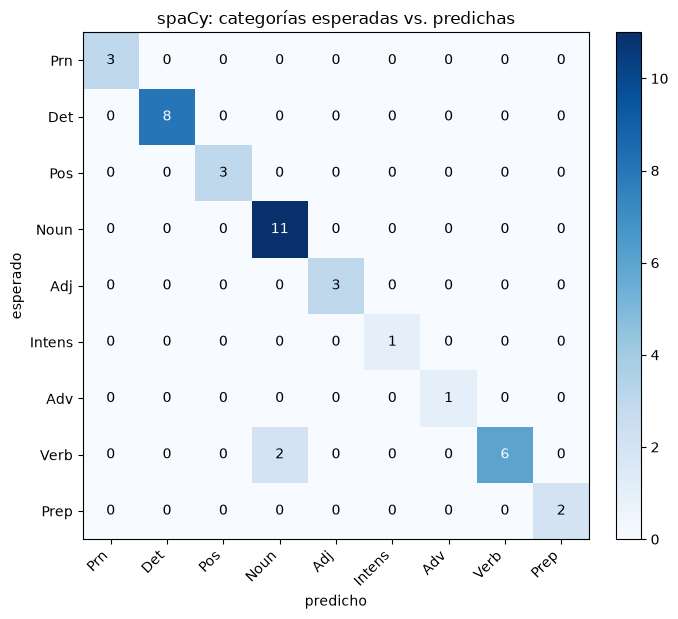

In [18]:
reports.plot_confusion(spacy_confusion, "spaCy: categorías esperadas vs. predichas",
                       FIGURES / "spacy_matriz_confusion.png")
plt.show()

In [19]:
spacy_report = reports.tag_report(y_true, y_pred)
spacy_report.to_csv(REPORTS / "spacy_reporte_clasificacion.csv")
spacy_report.round(3)

,precision,cobertura,f1,soporte
Prn,1.000,1.000,1.000,3
Det,1.000,1.000,1.000,8
Pos,1.000,1.000,1.000,3
Noun,0.846,1.000,0.917,11
Adj,1.000,1.000,1.000,3
Intens,1.000,1.000,1.000,1
Adv,1.000,1.000,1.000,1
Verb,1.000,0.750,0.857,8
Prep,1.000,1.000,1.000,2
promedio macro,0.983,0.972,0.975,40


In [ ]:
spacy_functions = reports.function_report(items, spacy_predictions)
spacy_functions.to_csv(REPORTS / "spacy_funciones.csv")
spacy_functions

In [20]:
# Resumen con todas las métricas de spaCy, también por nivel.
def spacy_summary(subset, name):
    ids = {i.id for i in subset}
    preds = [p for p in spacy_predictions if p.id in ids]
    yt, yp, skip = reports.tag_pairs(subset, preds)
    rep = reports.tag_report(yt, yp) if yt else None
    fun = reports.function_report(subset, preds)
    times = [p.time_ms for p in preds if not p.run_error]
    return {
        "nivel": name,
        "oraciones": len(subset),
        "palabras": len(yt),
        "exactitud_etiquetas": rep.loc["exactitud", "f1"] if rep is not None else None,
        "precision_macro": rep.loc["promedio macro", "precision"] if rep is not None else None,
        "cobertura_macro": rep.loc["promedio macro", "cobertura"] if rep is not None else None,
        "f1_macro": rep.loc["promedio macro", "f1"] if rep is not None else None,
        "f1_ponderado": rep.loc["promedio ponderado", "f1"] if rep is not None else None,
        "excluidas": len(skip),
        "sujeto": fun.loc["sujeto", "exactitud"],
        "verbo": fun.loc["verbo", "exactitud"],
        "objeto": fun.loc["objeto", "exactitud"],
        "tiempo_ms_promedio": sum(times) / len(times) if times else None,
    }


spacy_all = pd.DataFrame(
    [spacy_summary(items, "todos")]
    + [spacy_summary([i for i in items if i.level == lv], str(lv)) for lv in (1, 2, 3)]
).set_index("nivel")
spacy_all.to_csv(REPORTS / "spacy_resumen.csv")
spacy_all.round(3)

,oraciones,palabras,exactitud_etiquetas,precision_macro,cobertura_macro,f1_macro,f1_ponderado,excluidas,sujeto,verbo,objeto,tiempo_ms_promedio
nivel,,,,,,,,,,,,
todos,8,40,0.950,0.983,0.972,0.975,0.949,0,0.875,0.875,0.875,5.651
1,1,4,1.000,1.000,1.000,1.000,1.000,0,1.000,1.000,1.000,27.293
2,5,26,0.962,0.986,0.978,0.980,0.961,0,1.000,1.000,1.000,2.471
3,2,10,0.900,0.958,0.917,0.921,0.890,0,0.500,0.500,0.500,2.780


### 1.8 Hallazgos preliminares de spaCy

> Escritos con las 8 oraciones de ejemplo del conjunto de prueba y spaCy 3.8 con `es_core_news_sm` 3.8.0.
> **Volver a revisarlos cuando la Persona 4 complete el conjunto de prueba.**

1. **En las oraciones que nuestra gramática genera, spaCy acierta.** Las 5 tienen etiquetas, sujeto,
   verbo y objeto correctos.
2. **No detecta errores de concordancia, ni siquiera con sus rasgos.** En *"La elefante grises duerme."*
   etiqueta *elefante* como nombre propio (`PROPN`) sin género ni número, así que no hay nada que
   comparar con *la* ni con *grises*. Nuestra CFG con rasgos sí la rechaza.
3. **Sus fallos en oraciones cortas no tienen que ver con la concordancia.** En *"Los perros come."*
   etiqueta *come* como sustantivo, pero en *"Los perros comen."* (correcta) también falla: etiqueta
   *comen* como sustantivo y *perros* como raíz. El modelo pequeño es frágil con oraciones de sujeto y
   verbo sin objeto.
4. **Por la mayúscula inicial, no analiza bien el sujeto omitido.** *"Come la manzana."* sale con *Come*
   como nombre propio, pero *"come la manzana."* sale bien: verbo como raíz y *manzana* como objeto. Es
   justo un caso que la CFG **no puede** generar (sujeto omitido) y spaCy **sí** podría, si no fuera por
   la mayúscula.
5. **Ambigüedad de las PP: spaCy elige una lectura distinta a la nuestra.** En *"Él mató un elefante en
   sus pijamas"* y *"Mi niña comió la manzana con su perro"* une la PP al **verbo** (`obl`). Nuestro
   parser la une al **sustantivo más cercano**. Ninguno muestra que existe otra lectura: la CFG porque
   el parser elige una, y spaCy porque siempre devuelve un solo árbol.
6. **Matriz de confusión (sección 1.7): el único error de etiquetado es Verb → Noun.** De 40 palabras
   acierta 38 (exactitud 0,95). Las dos que falla son *come* en *"Los perros come."* y en *"Come la
   manzana."*, que son los hallazgos 3 y 4. Por eso `Verb` tiene cobertura 0,75 y `Noun` precisión 0,85;
   todas las demás categorías tienen 1,0. Por nivel, el 3 baja a 0,5 en sujeto, verbo y objeto por
   *"Come la manzana."* (spaCy toma *manzana* como verbo raíz). Con tan pocas oraciones, cada error
   mueve mucho los porcentajes.
7. **Tiempo:** unos 2 ms por oración. La primera oración tarda más (unos 9 ms) porque incluye la
   preparación del modelo, por eso el promedio del nivel 1 sale más alto.
8. **Errores que no cambian las métricas:** *come* con modo subjuntivo (`Mood=Sub`) en *"Ella come una
   manzana."*, *ayer* unido a *gris* en vez de al verbo, y *pijamas* marcado como femenino.

TODO(P1): probar un modelo más grande (`es_core_news_md`, `es_core_news_lg` o el de transformers,
`es_dep_news_trf`) para ver si los hallazgos 3 y 4 son límites del modelo pequeño o de spaCy en general.

## 2. HuggingFace Transformers

TODO(P1): elegir el modelo. Tiene que ser de **clasificación de tokens** (POS tagging) para español con
etiquetas UPOS. Buscarlo en huggingface.co (filtro *token-classification*, idioma *es*) y anotar en el
informe el nombre exacto, el tamaño y el tagset. Instalar antes `torch` y `transformers`
(están en `requirements-experiments.txt`).

Si el modelo solo hace POS, `sujeto`, `verbo` y `objeto` quedan en `null` (sección 2.4). Mientras `MODEL`
no esté definido, esta sección se salta y el resto del notebook corre igual.

In [ ]:
MODEL = "TODO(P1): nombre/del-modelo"
TRANSFORMERS_READY = not MODEL.startswith("TODO")

if TRANSFORMERS_READY:
    from transformers import pipeline

    tagger = pipeline("token-classification", model=MODEL, aggregation_strategy="simple")
else:
    print("Transformers: falta elegir MODEL; se salta esta sección.")

In [ ]:
from experiments.tagsets import upos_category


def transformers_tags(sentence: str) -> list[list[str]]:
    """[[palabra, categoría], ...] con la conversión de la sección 2.5 (sin rasgos).

    TODO(P1): revisar con salidas reales que cada entidad sea UNA palabra
    (aggregation_strategy) y que la etiqueta sea UPOS; si no, adaptar aquí.
    """
    tags = []
    for entity in tagger(sentence):
        word = entity["word"].strip().lower()
        category = upos_category(entity["entity_group"], word)
        if category is not None:
            tags.append([word, category])
    return tags


if TRANSFORMERS_READY:
    transformers_predictions = []
    for item in items:
        start = time.perf_counter()
        try:
            tags = transformers_tags(item.sentence)
            transformers_predictions.append(Prediction(
                item.id, "transformers", accepts=None, tags=tags,
                time_ms=round((time.perf_counter() - start) * 1000, 3)))
        except Exception as e:
            transformers_predictions.append(Prediction(item.id, "transformers", accepts=None,
                                                       run_error=f"{type(e).__name__}: {e}"))
    print("Guardado en", save_predictions("transformers", transformers_predictions, items))

## 3. Comparación con la CFG

Usa los resultados que existan en `results/`. El del parser lo genera la Persona 2 con
`python -m evaluation.run_parser`.

In [ ]:
systems = [s for s in ("parser", "spacy", "transformers") if results_path(s).exists()]
by_system = {s: {p.id: p for p in load_predictions(s)} for s in systems}
print("Sistemas con resultados:", ", ".join(systems))


def summary(item, pred):
    if pred is None or pred.run_error:
        return "—"
    decision = "" if pred.accepts is None else ("acepta, " if pred.accepts else f"rechaza ({pred.error_type}), ")
    tags = "etiquetas ✓" if pred.tags and [c for _, c in pred.tags] == [c for _, c in item.tags] else "etiquetas ✗"
    return decision + tags


pd.DataFrame([
    {"id": i.id, "oracion": i.sentence, "en_gramatica": i.in_grammar, "espanol_valido": i.valid_spanish,
     **{s: summary(i, by_system[s].get(i.id)) for s in systems}}
    for i in items
])

### Matriz de confusión de aceptación (parser y LLM)

Solo para los sistemas que deciden (`acepta` = `true`/`false`). Se compara contra `en_gramatica` (¿sigue
las reglas?) y contra `espanol_valido` (¿sigue su conocimiento del español?), como pide la sección 2.7 a.

In [ ]:
from experiments import reports

deciding = [s for s in ("parser", "llm_zero", "llm_few") if results_path(s).exists()]
if not deciding:
    print("Todavía no hay resultados de sistemas que decidan (parser o LLM).")
for system in deciding:
    preds = load_predictions(system)
    for reference in ("in_grammar", "valid_spanish"):
        matrix = reports.acceptance_confusion(items, preds, reference)
        print(f"\n{system} contra {reports.REFERENCES[reference]}")
        display(matrix)
        display(reports.acceptance_report(matrix).to_frame("valor").T)

### Conclusiones (para el informe)

TODO(P1), a partir de los hallazgos de la sección 1.8 y de los de Transformers:

- Oraciones que spaCy/Transformers analizan bien y la CFG no puede (sujeto omitido, orden libre,
  subordinadas, palabras fuera del léxico…).
- Oraciones que la CFG acierta y ellos no (concordancia: un etiquetador no las rechaza).
- Diferencia de fondo: reglas explícitas frente a modelos estadísticos.